# CSC14120 – Parallel Programming: Final Project
## Midterm Report: Proposal and Sequential Version (V0)

**Group:** Group13  
**Dataset:** [Google Drive – raw photos (Test-image)](https://drive.google.com/drive/folders/1I1R7S_vAQuiHQvDeO4-8cR18JTbKruVz?usp=drive_link). The prepared `dataset/` folder (16:9 crop + 3 sizes) and the synthetic pair are generated by the cells in Section 4, so nothing else needs to be downloaded.

> **How to use this notebook:** run *Runtime → Run all* on a fresh Colab session. The first code cell of Section 2 asks you to upload `Group13_Midterm.zip` (or reads `src/` from Drive).

**Contents**
1. Team information and work plan
2. Environment setup (build from `src/`)
3. Problem understanding
4. Dataset
5. Chosen methods
6. Sequential version (V0)
7. V0 results and profiling
8. GPU plan
9. References

## 1. Team information and work plan

### 1.1 Members

| # | Full name | Student ID |
|---|-----------|------------|
| 1 | Cao Trung Kien | 21127326 |
| 2 | Pham Hoang Khanh Dang | 21127588 |
| 3 | Le Van Hoang Tan | 23127471 |

### 1.2 Work plan until final submission

| Stage / version | Responsible member(s) | Planned finish (week) |
|---|---|---|
| Project planning | Dang | 7th |
| V0 sequential baseline | Kien | 7th |
| V1 naive CUDA (stages: see Section 8.1) | Tan | 7th |
| V2 optimized CUDA | Dang | 8th |
| V3 … | Kien | 9th |
| Benchmarking and report | Tan | 10th |
| Oral defense video and slides | All members | 11th |

## 2. Environment setup

The program is built from the submitted `src/` folder (single source of truth): the notebook never contains a second copy of the code. Pick **one** source with the `SOURCE` variable.

In [1]:
import os, re, glob, shutil, zipfile, subprocess, time

SOURCE = "upload"        # "upload": upload Group13_Midterm.zip  |  "drive": copy src/ from the team's Drive folder
DRIVE_SRC = "/content/drive/MyDrive/TODO/src"      # only used when SOURCE == "drive"

shutil.rmtree("/content/src", ignore_errors=True)
if SOURCE == "upload":
    from google.colab import files
    name = next(iter(files.upload()))                     # choose Group13_Midterm.zip
    zipfile.ZipFile(name).extractall("/content/_zip")
    main_cpp = glob.glob("/content/_zip/**/src/main.cpp", recursive=True)[0]
    shutil.copytree(os.path.dirname(main_cpp), "/content/src")
else:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(DRIVE_SRC, "/content/src")
os.chdir("/content")
print(sorted(os.listdir("/content/src")))

Saving GroupXX_Midterm.zip to GroupXX_Midterm.zip
['common.h', 'cuda_utils.cuh', 'io.h', 'main.cpp', 'stb_image.h', 'stb_image_write.h', 'stb_impl.cpp', 'v0_seq.cpp', 'versions.h']


In [2]:
%%bash
# Hardware / toolchain used for every timing in this report
lscpu | grep -E "Model name|^CPU\(s\)|Thread\(s\) per core|MHz"
g++ --version | head -n 1
nvidia-smi -L 2>/dev/null || echo "(no GPU in this runtime - not needed for V0)"

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Thread(s) per core:                      2
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
(no GPU in this runtime - not needed for V0)


In [3]:
%%bash
# Build V0 (CPU only). stb_impl.cpp compiles the stb implementations exactly once.
# No -fopenmp, no threads, no intrinsics: V0 stays a fair single-thread baseline.
# When a GPU version is added:  nvcc -O2 -std=c++17 src/main.cpp src/stb_impl.cpp src/v0_seq.cpp src/v1_<name>.cu -o stitch
cd /content
g++ -O2 -std=c++17 src/main.cpp src/stb_impl.cpp src/v0_seq.cpp -o stitch
ls -la stitch

-rwxr-xr-x 1 root root 221448 Nov 12 13:28 stitch


## 3. Problem understanding

Features are distinctive parts of a scene (corners, blobs, textures) that can be found again in another photo of the same scene. A typical feature detection and matching pipeline looks like this:
- Input: images from files or cameras
- Stage 1: image pre-processing
- Stage 2: feature detection
- Stage 3: feature description
- Stage 4: feature matching
- Next: the application

Panorama stitching is such an application, found in smartphones and in tools such as Adobe Photoshop or AutoPano Pro. Given two overlapping photos of the same scene, we produce one stitched panorama. The overlap provides the features that link the two images; the matches are then used to align and merge them:
- Stage 5: homography estimation (robustly, with RANSAC)
- Stage 6: warping and blending
- Output: the panorama

```
Image A ─► Stage 1-3 (Image A) ─┐
                                ├─► Stage 4-6 ─► Panorama
Image B ─► Stage 1-3 (Image B) ─┘
```

Our implementation has one extra optional step **before** Stage 1 (called `proj` in the timing tables): a cylindrical projection with an automatically searched focal length, which keeps the homography well behaved when the camera rotates a lot between the two shots. It can be disabled with `--focal 0` (planar). The stage names printed by the program map to the six report stages as follows:

| Report stage | Program stage name(s) | What it computes |
|---|---|---|
| (0) projection | `proj` | focal-length search + cylindrical projection of both images |
| 1 Pre-processing | `gray`, `blur` | RGB → grayscale, 5-tap binomial smoothing |
| 2 Detection | `fast` | FAST-9 corners, 3×3 non-max suppression, top-K |
| 3 Description | `brief` | oriented BRIEF-256 binary descriptors |
| 4 Matching | `match` | brute-force Hamming + ratio test + cross-check |
| 5 Homography | `ransac` | RANSAC with 4-point DLT + refit on inliers |
| 6 Warping + blending | `warp` | canvas, inverse bilinear warp, exposure gain, seam, multi-band blend |
| (GPU only) | `h2d`, `d2h` | host↔device transfers (always 0 in V0) |

## 4. Dataset

Requirements: at least **3 sites**, **1 standard pair per site**, and **1 challenging pair**.

Raw images come from the Google Drive folder linked at the top, taken by LG V50 ThinQ (using base camera app from LineageOS 22.2 (AOSP 15)). Each pair is processed with the same operations on the left and right images:
- centre-cropped to 16:9, then
- resized to three sizes: small (1280×720), medium (1920×1080), large (3840×2160).

| Site | Description / location | Pair type | Resolutions available |
|---|---|---|---|
| 1 | `indoor1` | standard | small, medium, large |
| 2 | `outdoor1` | standard | small, medium, large |
| 3 | `outdoor2` | standard | small, medium, large |
| 4 | `outdoor3` (night scene with moving cars) | challenging | small, medium, large |


In [4]:
# (1) Download the raw photos (the Drive folder must be shared as "Anyone with the link")
DATASET_URL = "https://drive.google.com/drive/folders/1I1R7S_vAQuiHQvDeO4-8cR18JTbKruVz?usp=drive_link"
if len(glob.glob("Test-image/*.jpg")) == 0:
    subprocess.run(["pip", "install", "-q", "gdown"], check=True)
    import gdown
    gdown.download_folder(DATASET_URL, output="Test-image", quiet=True, use_cookies=False)
print("Test-image:", len(glob.glob("Test-image/*")), "files")

Test-image: 18 files


In [5]:
# (2) Crop to 16:9 and resize to three sizes.  PAIRS = (site, pair type, LEFT image, RIGHT image)
from PIL import Image, ImageOps
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SIZES = {"small": (1280, 720), "medium": (1920, 1080), "large": (3840, 2160)}
PAIRS = [
    ("indoor1",  "standard",    "Test-image/indoor1_2.jpg",  "Test-image/indoor1_3.jpg"),
    ("outdoor1", "standard",    "Test-image/outdoor1_2.jpg", "Test-image/outdoor1_3.jpg"),
    ("outdoor2", "standard",    "Test-image/outdoor2_1.jpg", "Test-image/outdoor2_2.jpg"),
    ("outdoor3", "challenging", "Test-image/outdoor3_1.jpg", "Test-image/outdoor3_2.jpg"),
]

def crop_16x9(im):
    """Centre crop to 16:9 (the same crop is applied to the left and the right photo)."""
    w, h = im.size
    new_h = round(w * 9 / 16)
    if new_h <= h:
        top = (h - new_h) // 2
        return im.crop((0, top, w, top + new_h))
    new_w = round(h * 16 / 9)
    left = (w - new_w) // 2
    return im.crop((left, 0, left + new_w, h))

def make_sizes(path, site, side):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")      # honour the EXIF orientation
    im = crop_16x9(im)
    for name, (W, H) in SIZES.items():
        os.makedirs(f"dataset/{name}", exist_ok=True)
        im.resize((W, H), Image.LANCZOS).save(f"dataset/{name}/{site}_{side}.png", compress_level=1)
    return im.size

for site, kind, left, right in PAIRS:
    for side, path in (("L", left), ("R", right)):
        assert os.path.exists(path), f"missing image: {path}"
        cw, ch = make_sizes(path, site, side)
    print(f"{site:9s} [{kind:11s}] crop 16:9 -> {cw}x{ch}  ->  " + ", ".join(f"{n} {w}x{h}" for n, (w, h) in SIZES.items()))
print(sorted(os.listdir("dataset")))

indoor1   [standard   ] crop 16:9 -> 4656x2619  ->  small 1280x720, medium 1920x1080, large 3840x2160
outdoor1  [standard   ] crop 16:9 -> 4032x2268  ->  small 1280x720, medium 1920x1080, large 3840x2160
outdoor2  [standard   ] crop 16:9 -> 4032x2268  ->  small 1280x720, medium 1920x1080, large 3840x2160
outdoor3  [challenging] crop 16:9 -> 4032x2268  ->  small 1280x720, medium 1920x1080, large 3840x2160
['large', 'medium', 'small']


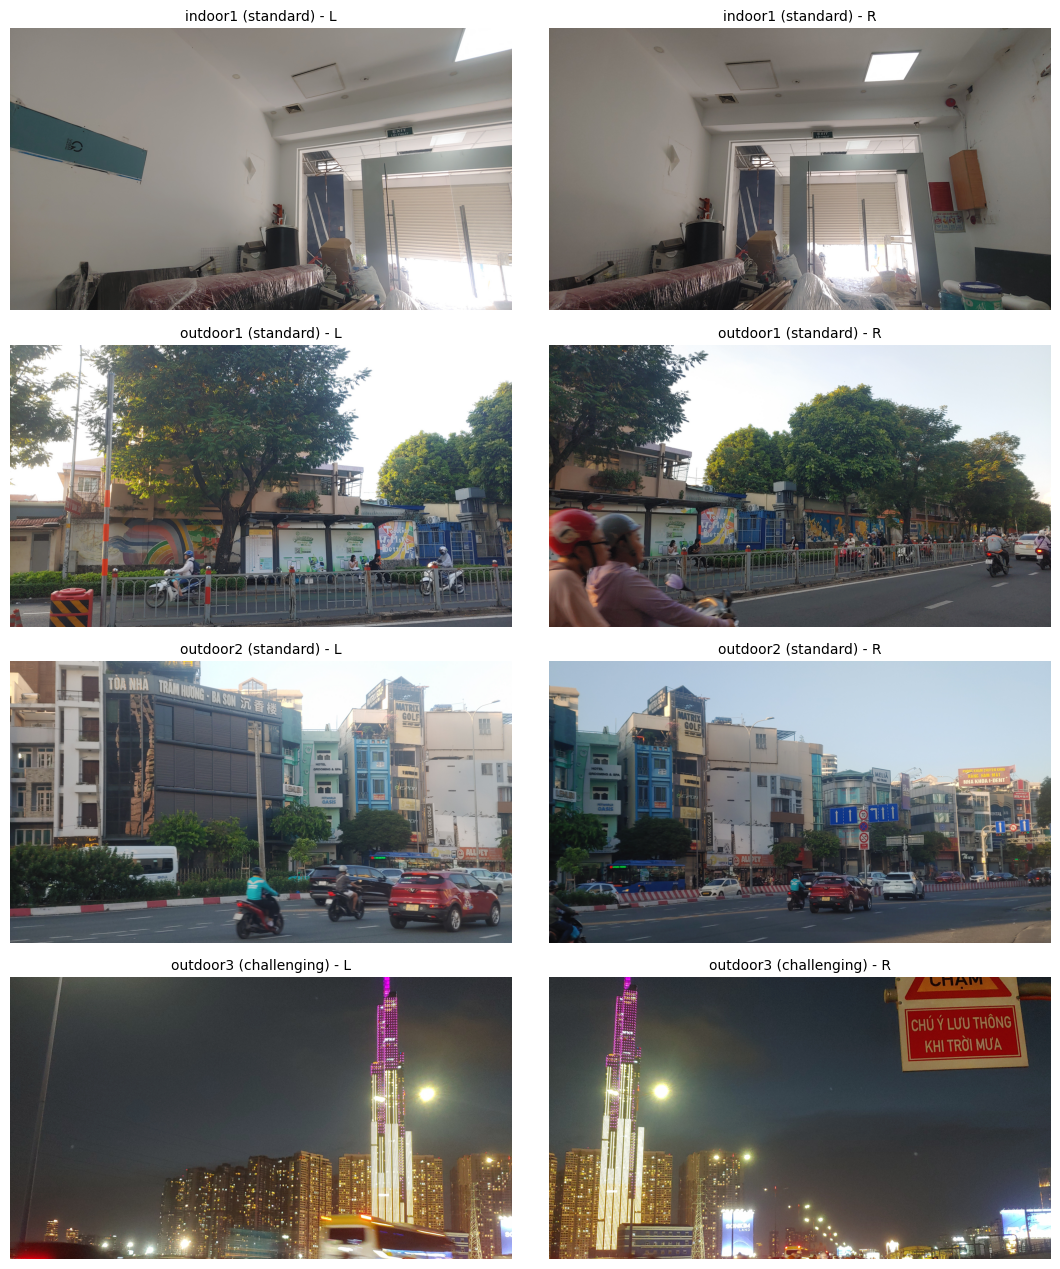

In [6]:
# (3) Preview: one standard pair per site and the challenging pair (medium size)
fig, axes = plt.subplots(len(PAIRS), 2, figsize=(11, 3.2 * len(PAIRS)))
for row, (site, kind, _, _) in zip(axes, PAIRS):
    for ax, side in zip(row, "LR"):
        im = Image.open(f"dataset/medium/{site}_{side}.png")
        ax.imshow(im); ax.axis("off"); ax.set_title(f"{site} ({kind}) - {side}", fontsize=10)
plt.tight_layout(); plt.show()

In [7]:
# (4) Synthetic pair with a KNOWN homography (same algorithm as data/make_synthetic_pair.py, fixed seed -> reproducible)
from PIL import ImageDraw, ImageFilter
os.makedirs("data", exist_ok=True)
rng = np.random.default_rng(1)
W, H = 2100, 720
base = np.zeros((H, W, 3), float)
for s, a in [(4, 40), (16, 60), (64, 50)]:                          # multi-scale noise
    n = rng.random((H // s + 2, W // s + 2, 3))
    im = Image.fromarray((n * 255).astype(np.uint8)).resize((W, H), Image.BICUBIC)
    base += a * (np.asarray(im) / 255.0 - 0.5) * 2
base += 128
img = Image.fromarray(np.clip(base, 0, 255).astype(np.uint8))
d = ImageDraw.Draw(img)
for i in range(120):                                                # random rectangles = corners
    x, y = rng.integers(0, W), rng.integers(0, H); w, h = rng.integers(10, 60, 2)
    d.rectangle([x, y, x + w, y + h], fill=tuple(int(v) for v in rng.integers(0, 255, 3)))
img = img.filter(ImageFilter.GaussianBlur(0.8))
A = img.crop((0, 0, 1280, 720))
c = (1.0, 0.03, 700.0, -0.03, 1.0, 5.0, 2e-5, 0.0)                  # ground truth: pixel of B -> coordinates of A
B = img.transform((1280, 720), Image.PERSPECTIVE, c, Image.BICUBIC)
A.save("data/A.ppm"); B.save("data/B.ppm")
print("data:", sorted(os.listdir("data")))

data: ['A.ppm', 'B.ppm']


## 5. Chosen methods

### 5.1 Exploration with an OpenCV prototype

To compare candidate pipelines quickly we first prototyped them in Python/OpenCV (V0 below is a separate, from-scratch C++ implementation). We kept some stages fixed because they matter little for the comparison, and varied the others:
- Stage 1 (pre-processing): grayscale
- Stage 4 (matching): brute-force Hamming + Lowe's ratio test
- Stage 5 (homography): RANSAC
- Stage 6 (warping): bilinear sampling

| Version | Stage 2: Detect | Stage 3: Describe | Stage 6: Blend |
|---|---|---|---|
| A1 | FAST | BRIEF | feather |
| A2 | Shi-Tomasi | BRIEF | feather |
| A3 | ORB | ORB | feather |
| B1 | FAST | BRIEF | multi-band |
| B2 | ORB | ORB | multi-band |

**Detector / descriptor (A1–A3).**
- Rotation and scale change are not the main problem in panorama stitching, and every method worked well on outdoor or far-away scenes. Most of them struggled on indoor images.
- On indoor images most methods left ghost images of close objects. This is the [parallax problem](https://www.panohelp.com/panoramicpivotpoint.html): one homography cannot align objects at different depths.
- In our experiments `FAST` and `ORB` were more robust to parallax and gave better images.

![Indoor1, FAST](https://i.ibb.co/chtMb7c2/indoor1-A1-FAST-BRIEF-feather.png)
*Fig 1: pipeline `A1` on `indoor1`*

![Indoor1, Shi-Tomasi](https://i.ibb.co/6JyWkJ38/indoor1-A2-Shi-Tomasi-BRIEF-feather.png)
*Fig 2: pipeline `A2` on `indoor1`*

![Indoor1, ORB](https://i.ibb.co/PZ590t6b/indoor1-A3-ORB-feather.png)
*Fig 3: pipeline `A3` on `indoor1`*

**Blending (B1-B2).**
- Feather blending can look blurry but makes the transition between the two images smooth.
- Multi-band blending preserves fine detail, but it does not fix geometric misalignment, so a misaligned seam stays visible.

![Outdoor2, FAST, feather](https://i.ibb.co/rRn244Q2/A1-FAST-BRIEF-feather.png)
*Fig 4: pipeline `A1` on `outdoor2`*

![Outdoor2, FAST, multi-band](https://i.ibb.co/k6W2MqDN/B1-FAST-BRIEF-multiband.png)
*Fig 5: pipeline `B1` on `outdoor2`*

**Conclusion of the exploration.** FAST + BRIEF is cheaper than ORB and gave comparable or better images, so the detector/descriptor pair for V0 is FAST + BRIEF.

### 5.2 What V0 actually uses

The parameters below are printed straight from `src/common.h` (the single header shared by all versions), so the tables that follow always match the code.

In [8]:
%%bash
# Parameters of V0 exactly as compiled
sed -n '/^namespace P {/,/^}/p' /content/src/common.h

namespace P {
// Stage 1: grayscale (integer weights, exact on CPU and GPU) + 5-tap binomial blur (sum 16, 2D sum 256)
constexpr int BLUR_W[5] = {1, 4, 6, 4, 1};
// Stage 2: FAST-9 on the blurred image
constexpr int FAST_T   = 20;     // contrast threshold
constexpr int BORDER   = 22;     // keypoints must be >= BORDER px from the image edge (rotated BRIEF pattern reaches 21 px)
constexpr int TOPK = 8000;   // keypoints kept per image
// Stage 3: BRIEF-256 on the blurred image
constexpr int BRIEF_BITS  = 256;
constexpr int BRIEF_WORDS = 8;   // 8 x uint32
constexpr uint32_t BRIEF_SEED = 12345u;
// Oriented BRIEF (ORB-style): the keypoint orientation is the direction of the intensity centroid of a disc of radius
// ORI_RADIUS, quantised to ORI_BINS directions; the 256-pair pattern is pre-rotated once per bin (integer tables).
constexpr int ORI_BINS   = 30;   // 12 degree steps
constexpr int ORI_RADIUS = 15;
// Stage 4: matching (Hamming, ratio test, cross-check)
constexpr int MAX_HAMMIN


**Final pipeline implemented in V0:**
1. (Optional) cylindrical projection with automatic focal-length search
2. Grayscale + 5-tap binomial blur
3. FAST-9 with 3×3 non-max suppression, top-K keypoints
4. Oriented BRIEF-256
5. Brute-force Hamming matching with ratio test and cross-check
6. RANSAC homography (4-point DLT, refit on inliers)
7. Inverse bilinear warp, exposure gain, seam-cut blend with multi-band smoothing

## 6. Sequential version (V0)

### 6.1 Design

All parameters live in one header (`src/common.h`) that every version includes, so all versions use *identical* settings. Integer arithmetic is used wherever possible so that CPU and GPU results can match exactly. V0 is single-threaded C++ (`src/v0_seq.cpp`, driven by `src/main.cpp`): no OpenMP, no `std::thread`, no hand-written SIMD. Timing uses `std::chrono` around each stage; disk I/O is excluded from `total(e2e)`.

Parameter values are those printed in Section 5.2.

| Stage | Method | Why (quality) | Why (parallel efficiency) |
|---|---|---|---|
| 0 Projection | Cylindrical projection, focal length searched on 1/`FOCAL_DOWNSCALE` copies over `FOCAL_FRAC` candidates; the candidate whose homography is closest to a translation wins | Keeps the homography well behaved after large camera rotation | Per-pixel gather; the search re-runs stages 1–5 several times on small images |
| 1 Pre-process | Integer grayscale (77,150,29)/256; separable 5-tap binomial blur | BRIEF needs smoothing to be noise-robust | Separable: 2k instead of k² work per pixel; stencil → shared-memory tiling |
| 2 Keypoints | FAST-9 (threshold `FAST_T`), 3×3 NMS, top-`TOPK` | Cheap, repeatable corners | One thread per pixel; compaction and top-K selection are the interesting parallel patterns |
| 3 Description | Oriented BRIEF-256: orientation from the intensity centroid of a disc (radius `ORI_RADIUS`), pattern pre-rotated for `ORI_BINS` directions, fixed seed | Rotation-aware, so tolerant to the camera rotating between shots | 256-bit binary descriptors = 8 × `uint32`; independent per keypoint |
| 4 Matching | Brute-force Hamming, ratio test `RATIO_NUM/RATIO_DEN`, max distance `MAX_HAMMING`, cross-check | Ratio test + cross-check remove ambiguous matches | All-pairs like a matrix product: shared-memory tiling + `__popc` |
| 5 Homography | RANSAC (`RANSAC_ITERS` hypotheses from a pre-generated sample table), 4-point normalized DLT, `RANSAC_THRESH` px, `REFINE_ROUNDS` least-squares refits | Robust to wrong matches | Hypotheses are independent → one thread/warp per hypothesis; inlier count is a reduction |
| 6 Warp / blend | Inverse warp with bilinear sampling, per-channel exposure gain, DP seam cut + multi-band (`MB_LEVELS`) | No holes; hides brightness steps; no ghosting under parallax | Gather per output pixel (texture memory for bilinear); the seam DP and pyramid levels are the harder parts |

### 6.2 Code origin and citations

| File | Authors | External source |
|---|---|---|
| `common.h`, `versions.h`, `main.cpp`, `v0_seq.cpp`, `cuda_utils.cuh` | original | none |
| `io.h` | original | `stb_image.h` / `stb_image_write.h` loaded through stb (Sean Barrett, public domain) |
| `stb_impl.cpp`, `stb_image.h`, `stb_image_write.h` | third-party | [nothings/stb](https://github.com/nothings/stb), public domain |

## 7. V0 results and profiling

### 7.1 Correctness: synthetic pair

`data/A.ppm` and `data/B.ppm` (Section 4) were generated with a known homography mapping **B pixels → A coordinates**. V0 runs with `--focal 0` (planar, no cylindrical projection) so that the estimated `H` is directly comparable with the ground truth. The error is the distance in pixels between the two transforms on a 5×5 grid of points in image B.

In [9]:
H_TRUE = np.array([[1.0,   0.03, 700.0],
                   [-0.03, 1.0,    5.0],
                   [2e-5,  0.0,    1.0]])          # = the coefficients c used to generate B in Section 4

r = subprocess.run(["./stitch", "data/A.ppm", "data/B.ppm", "pano_synthetic.png",
                    "--version", "0", "--runs", "1", "--focal", "0"], capture_output=True, text=True)
print(r.stdout.split("stage times")[0])

m = re.search(r"H = \[(.*?)\]", r.stdout)
H_EST = np.array([float(x) for x in m.group(1).replace(";", " ").split()]).reshape(3, 3)
H_EST /= H_EST[2, 2]

def warp_pts(H, pts):
    q = np.c_[pts, np.ones(len(pts))] @ H.T
    return q[:, :2] / q[:, 2:3]

W_, H_ = 1280, 720
gx, gy = np.meshgrid(np.linspace(0, W_ - 1, 5), np.linspace(0, H_ - 1, 5))
pts = np.c_[gx.ravel(), gy.ravel()]
err = np.linalg.norm(warp_pts(H_EST, pts) - warp_pts(H_TRUE, pts), axis=1)

print("H ground truth:", np.round(H_TRUE.ravel(), 6))
print("H estimated   :", np.round(H_EST.ravel(), 6))
print(f"Homography error on a 5x5 grid of B: mean = {err.mean():.3f} px | max = {err.max():.3f} px")

version=0  input=1280x720  runs=1  device=CPU(single thread)
keypoints A/B: 208/263  matches: 72  inliers: 70  stitched: yes
H = [ 1.00196  0.03137  699.69619; -0.02989  1.00137  4.78178;  0.000021  0.000001  1.000000]
projection: planar

H ground truth: [ 1.e+00  3.e-02  7.e+02 -3.e-02  1.e+00  5.e+00  2.e-05  0.e+00  1.e+00]
H estimated   : [ 1.0019600e+00  3.1370000e-02  6.9969619e+02 -2.9890000e-02
  1.0013700e+00  4.7817800e+00  2.1000000e-05  1.0000000e-06
  1.0000000e+00]
Homography error on a 5x5 grid of B: mean = 0.242 px | max = 0.806 px


### 7.2 Run V0 on every pair × 3 sizes

Each `./stitch` call performs one untimed warm-up run, then `RUNS` timed runs; the reported value of every stage is the **mean over the timed runs** (ms). Panoramas go to `results/pano_v0_<site>_<size>.png` and all numbers to `results/timing_v0.csv`. `large` uses fewer runs because a sequential run is slow. `FOCAL = None` keeps the program's default (automatic focal-length search).

In [10]:
VERSION = 0
RUNS    = {"small": 5, "medium": 5, "large": 3}
FOCAL   = None                     # None = automatic focal search (default) | 0 = planar | >0 = fixed focal / width
STAGES  = ["proj", "gray", "blur", "fast", "brief", "match", "ransac", "warp", "h2d", "d2h"]   # order used in the tables

os.makedirs("results", exist_ok=True)

def parse_output(out):
    """Parse ./stitch stdout: keypoint counts, projection, panorama size and mean time of each stage."""
    d = {}
    m = re.search(r"keypoints A/B: (\d+)/(\d+)\s+matches: (\d+)\s+inliers: (\d+)", out)
    if m: d.update(kpA=int(m[1]), kpB=int(m[2]), matches=int(m[3]), inliers=int(m[4]))
    m = re.search(r"projection: (\w+)", out);          d["projection"] = m[1] if m else ""
    m = re.search(r"panorama (\d+)x(\d+)", out)
    d["pano_w"], d["pano_h"] = (int(m[1]), int(m[2])) if m else (0, 0)
    for line in out.splitlines():                        # e.g. "  warp   245.724 |   245.724"  (mean | min)
        m = re.match(r"\s+(\S+)\s+([\d.]+)\s*\|\s*([\d.]+)\s*$", line)
        if m: d[m[1]] = float(m[2])
    return d

def run_pair(site, kind, size):
    L, R = f"dataset/{size}/{site}_L.png", f"dataset/{size}/{site}_R.png"
    out = f"results/pano_v{VERSION}_{site}_{size}.png"
    cmd = ["./stitch", L, R, out, "--version", str(VERSION), "--runs", str(RUNS[size])]
    if FOCAL is not None: cmd += ["--focal", str(FOCAL)]
    t0 = time.time()
    r = subprocess.run(cmd, capture_output=True, text=True)
    row = dict(site=site, kind=kind, size=size, W=SIZES[size][0], H=SIZES[size][1],
               ok=(r.returncode == 0), wall_s=round(time.time() - t0, 1))
    row.update(parse_output(r.stdout))
    if r.returncode == 1: print(r.stderr)               # file read/write error
    return row

rows = []
for site, kind, _, _ in PAIRS:
    for size in SIZES:
        row = run_pair(site, kind, size); rows.append(row)
        print(f"{site:9s} {size:6s} {row['W']}x{row['H']}  {'OK  ' if row['ok'] else 'FAIL'}  inliers={row.get('inliers','-'):>5}  "
              f"total={row.get('total(e2e)', float('nan')):9.1f} ms  ({row['wall_s']} s)")

df = pd.DataFrame(rows)
df.to_csv(f"results/timing_v{VERSION}.csv", index=False)

indoor1   small  1280x720  OK    inliers=   73  total=    799.9 ms  (5.4 s)
indoor1   medium 1920x1080  OK    inliers=   76  total=    911.4 ms  (6.2 s)
indoor1   large  3840x2160  OK    inliers=  106  total=   4202.5 ms  (19.9 s)
outdoor1  small  1280x720  OK    inliers=  502  total=   1010.4 ms  (7.0 s)
outdoor1  medium 1920x1080  OK    inliers=  890  total=   4322.1 ms  (26.2 s)
outdoor1  large  3840x2160  OK    inliers=  401  total=  10681.5 ms  (48.3 s)
outdoor2  small  1280x720  OK    inliers=  275  total=   1122.9 ms  (7.7 s)
outdoor2  medium 1920x1080  OK    inliers=  318  total=   1977.3 ms  (12.6 s)
outdoor2  large  3840x2160  OK    inliers=  158  total=   7347.6 ms  (35.1 s)
outdoor3  small  1280x720  OK    inliers=  603  total=    841.9 ms  (5.6 s)
outdoor3  medium 1920x1080  OK    inliers=  709  total=   2375.8 ms  (15.2 s)
outdoor3  large  3840x2160  OK    inliers=  261  total=  10125.5 ms  (46.7 s)


### 7.3 Panoramas (one per site)

The stitched panorama of each standard pair (one per site) and of the challenging pair, at medium size. The other sizes are in `results/`.

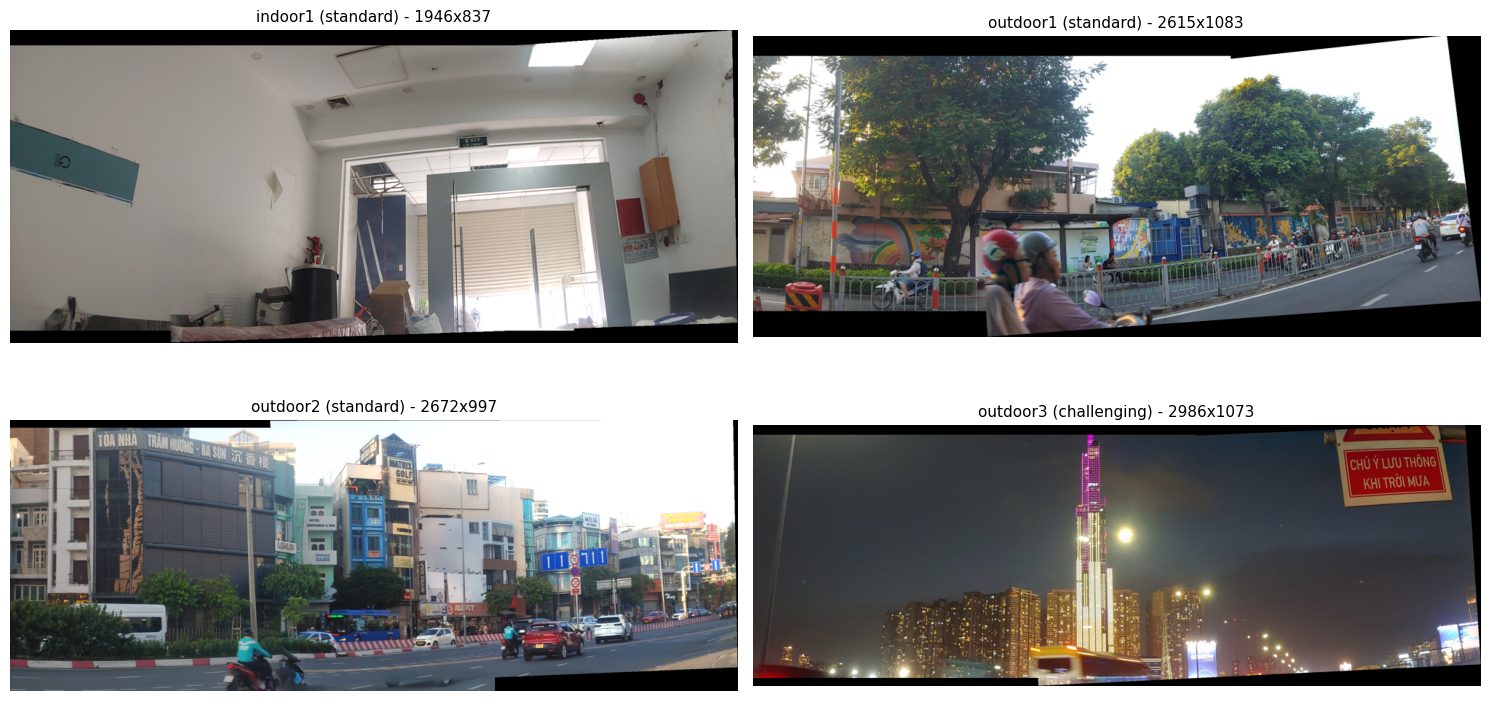

In [11]:
SHOW_SIZE = "medium"
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (site, kind, _, _) in zip(axes.ravel(), PAIRS):
    p = f"results/pano_v{VERSION}_{site}_{SHOW_SIZE}.png"
    ax.axis("off")
    if os.path.exists(p):
        im = Image.open(p); w, h = im.size; im.thumbnail((1000, 700))
        ax.imshow(im); ax.set_title(f"{site} ({kind}) - {w}x{h}", fontsize=11)
    else:
        ax.set_title(f"{site} ({kind}) - STITCHING FAILED (not enough inliers)", fontsize=11, color="red")
plt.tight_layout(); plt.show()

### 7.4 Per-stage timing (small / medium / large)

Mean over the **standard** pairs (the challenging pair is excluded from the average because it may fail or have a very different keypoint count; its numbers are listed in the per-pair table). `other` = `total(e2e)` minus the sum of the listed stages (cost that belongs to no stage). Times are single-thread CPU wall-clock; disk I/O is excluded.

In [12]:
std = df[(df.kind == "standard") & df.ok]
cols = STAGES + ["total(e2e)"]
tab = std.groupby("size")[cols].mean().reindex(list(SIZES)).T
tab.loc["other"] = tab.loc["total(e2e)"] - tab.loc[STAGES].sum()
tab = tab.loc[STAGES + ["other", "total(e2e)"]]
tab.columns = [f"{s} ({SIZES[s][0]}x{SIZES[s][1]})" for s in tab.columns]
print(f"V0 time (ms), mean over {std.site.nunique()} standard pairs\n")
display(tab.round(2))

# per-pair numbers (for the appendix / cross-checking)
display(df[["site", "kind", "size", "ok", "kpA", "kpB", "matches", "inliers", "projection", "pano_w", "pano_h", "total(e2e)"]].round(1))

V0 time (ms), mean over 3 standard pairs



,small (1280x720),medium (1920x1080),large (3840x2160)
proj,195.39,339.78,1722.85
gray,3.78,6.49,30.97
blur,39.84,71.10,298.23
fast,68.33,135.97,551.26
brief,13.08,28.17,41.70
match,180.80,1051.35,1472.67
ransac,6.95,9.78,8.73
warp,469.52,760.97,3281.80
h2d,0.00,0.00,0.00
d2h,0.00,0.00,0.00


,site,kind,size,ok,kpA,kpB,matches,inliers,projection,pano_w,pano_h,total(e2e)
0,indoor1,standard,small,True,263,306,103,73,cylindrical,1338,574,799.9
1,indoor1,standard,medium,True,402,574,133,76,cylindrical,1946,837,911.4
2,indoor1,standard,large,True,866,1289,232,106,cylindrical,3908,1679,4202.5
3,outdoor1,standard,small,True,3205,2443,540,502,cylindrical,1731,720,1010.4
4,outdoor1,standard,medium,True,7397,5932,1053,890,cylindrical,2615,1083,4322.1
5,outdoor1,standard,large,True,8000,8000,661,401,cylindrical,5184,2165,10681.5
6,outdoor2,standard,small,True,2067,1935,323,275,planar,2371,1037,1122.9
7,outdoor2,standard,medium,True,2860,2746,404,318,cylindrical,2672,997,1977.3
8,outdoor2,standard,large,True,5063,4907,412,158,cylindrical,5246,2016,7347.6
9,outdoor3,challenging,small,True,2119,1863,624,603,cylindrical,1995,718,841.9


### 7.5 Hot stages

The pixel count of *medium* is 2.25× that of *small* and *large* is 9×. A stage whose time grows close to 9× scales with the number of pixels; a much smaller growth usually means it depends on the number of keypoints/matches (bounded by `TOPK`) rather than on pixels.

Share of each stage in the total time (%):


,small,medium,large
proj,20.0,14.1,23.2
gray,0.4,0.3,0.4
blur,4.1,3.0,4.0
fast,7.0,5.7,7.4
brief,1.3,1.2,0.6
match,18.5,43.7,19.9
ransac,0.7,0.4,0.1
warp,48.0,31.7,44.3
h2d,0.0,0.0,0.0
d2h,0.0,0.0,0.0


Time growth relative to small:


,small,medium,large
proj,1.0,1.74,8.82
gray,1.0,1.72,8.18
blur,1.0,1.78,7.48
fast,1.0,1.99,8.07
brief,1.0,2.15,3.19
match,1.0,5.81,8.15
ransac,1.0,1.41,1.26
warp,1.0,1.62,6.99
total(e2e),1.0,2.46,7.58
(pixel count),1.0,2.25,9.00


small  - hot stages: warp 48.0%, proj 20.0%, match 18.5%
medium - hot stages: match 43.7%, warp 31.7%, proj 14.1%
large  - hot stages: warp 44.3%, proj 23.2%, match 19.9%


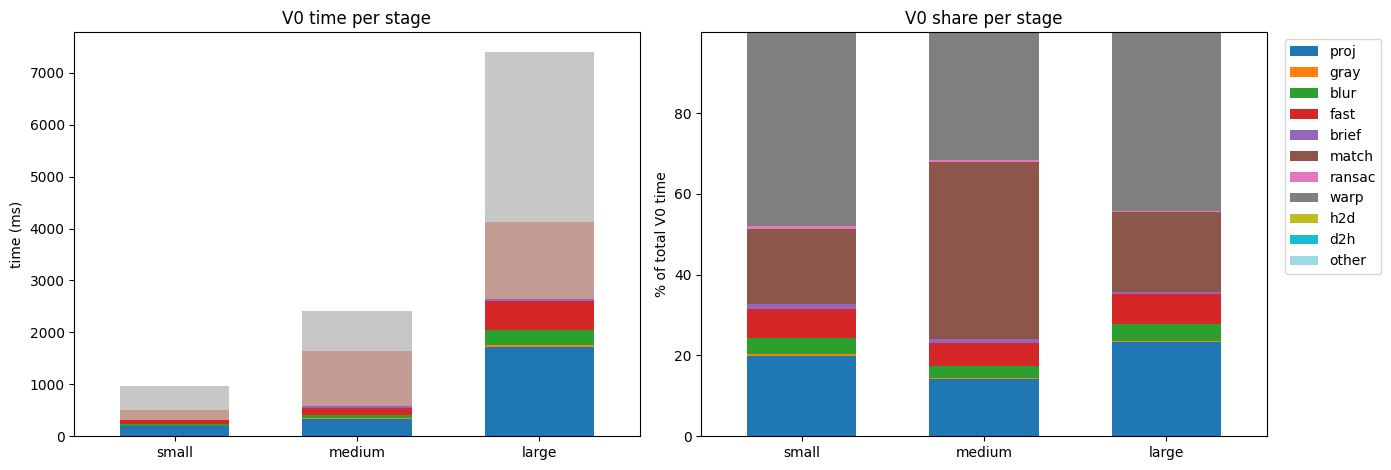

In [13]:
t = tab.copy(); t.columns = list(SIZES)
pct = (t.loc[STAGES + ["other"]] / t.loc["total(e2e)"] * 100)
print("Share of each stage in the total time (%):")
display(pct.round(1))

growth = (t[list(SIZES)].div(t["small"], axis=0)).loc[[s for s in STAGES if t.loc[s, "small"] > 0] + ["total(e2e)"]]
growth.loc["(pixel count)"] = [(w * h) / (1280 * 720) for w, h in SIZES.values()]
print("Time growth relative to small:")
display(growth.round(2))

for s in SIZES:
    top = pct[s].drop("other").sort_values(ascending=False).head(3)
    print(f"{s:6s} - hot stages:", ", ".join(f"{k} {v:.1f}%" for k, v in top.items()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
t.loc[STAGES].T.plot.bar(stacked=True, ax=axes[0], colormap="tab20", width=0.6, legend=False)
axes[0].set_ylabel("time (ms)"); axes[0].set_title("V0 time per stage")
pct.T.plot.bar(stacked=True, ax=axes[1], colormap="tab20", width=0.6)
axes[1].set_ylabel("% of total V0 time"); axes[1].set_title("V0 share per stage")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 7.6 Amdahl estimate

If the stages we plan to accelerate take a fraction *p* of V0's time, the end-to-end speedup can never exceed 1/(1 − *p*), however fast the GPU part becomes. `p` is computed on `total(e2e)`. Edit `ACCEL` to the stages decided in Section 8.1 (`h2d`/`d2h` are 0 in V0 and are not accelerated stages).

In [14]:
ACCEL = ["gray", "blur", "fast", "brief", "match", "ransac", "warp"]     # stages planned for the GPU (see 8.1); add "proj" if it is also planned

rows_a = []
for s in SIZES:
    p = t.loc[ACCEL, s].sum() / t.loc["total(e2e)", s]
    row = {"size": f"{s} ({SIZES[s][0]}x{SIZES[s][1]})", "V0 total (ms)": t.loc["total(e2e)", s],
           "accelerated (ms)": t.loc[ACCEL, s].sum(), "p": p,
           "limit 1/(1-p)": 1 / (1 - p) if p < 1 else float("inf")}
    for sp in (10, 50, 100):                                  # speedup if the accelerated part becomes sp times faster
        row[f"speedup if GPU part x{sp}"] = 1 / ((1 - p) + p / sp)
    rows_a.append(row)

amdahl = pd.DataFrame(rows_a).set_index("size")
print("Accelerated stages:", ACCEL)
display(amdahl.round(3))
for s, r_ in amdahl.iterrows():
    print(f"{s:20s} p = {r_['p']:.3f}  ->  maximum speedup = {r_['limit 1/(1-p)']:.2f}x")

Accelerated stages: ['gray', 'blur', 'fast', 'brief', 'match', 'ransac', 'warp']


,V0 total (ms),accelerated (ms),p,limit 1/(1-p),speedup if GPU part x10,speedup if GPU part x50,speedup if GPU part x100
size,,,,,,,
small (1280x720),977.710,782.316,0.800,5.004,3.573,4.633,4.811
medium (1920x1080),2403.624,2063.837,0.859,7.074,4.401,6.308,6.669
large (3840x2160),7410.549,5685.354,0.767,4.295,3.231,4.030,4.158


small (1280x720)     p = 0.800  ->  maximum speedup = 5.00x
medium (1920x1080)   p = 0.859  ->  maximum speedup = 7.07x
large (3840x2160)    p = 0.767  ->  maximum speedup = 4.30x


## 8. GPU plan

### 8.1 Stages moved to the GPU and why

The proposal below follows the structure of the pipeline; **confirm or change each row with the profile in Section 7.4–7.6** (a stage with a negligible share is not worth the transfer cost).

| Stage | Move to GPU? | Reason |
|---|---|---|
| `gray`, `blur` | Yes | Per-pixel and stencil work, data-parallel; scales with the pixel count.|
| `fast` | Yes | One independent test per pixel (16-pixel ring).|
| `brief` | Yes | Independent per keypoint, `TOPK` keypoints per image.|
| `match` | Yes | All-pairs Hamming distances, matrix-product-like.|
| `ransac` | Yes | `RANSAC_ITERS` independent hypotheses.|
| `warp` | Yes | Gather per canvas pixel; seam DP is the hard part.|

### 8.2 Planned thread mapping for V1

| Stage | One thread computes… | One warp computes… | One block computes… | Notes |
|---|---|---|---|---|
| `gray` | one output pixel | – | a 2-D tile of pixels | fused with the blur's first pass |
| `blur` | one output pixel per pass (horizontal, then vertical) | – | a tile + 2-pixel halo in shared memory | integer arithmetic keeps CPU/GPU bit-exact |
| `fast` | the FAST score of one pixel | – | a tile of pixels | NMS needs the score map; keypoints are compacted with an atomic counter or a prefix sum, then top-`TOPK` |
| `brief` | one keypoint (orientation, then 256 comparisons) | one keypoint (lanes split the 256 pairs, `__ballot_sync` builds the 32-bit words) | several keypoints | irregular reads of the blurred image; pre-rotated pattern table is read-only |
| `match` | one keypoint of A against all of B | – | a tile of A descriptors against tiles of B staged in shared memory | `__popc` on 8 words; best/second-best per row; cross-check needs the reverse direction |
| `ransac` | one hypothesis (4-point DLT, then the inlier count over all matches) | – | a group of hypotheses; block-wide reduction picks the best | sample table is pre-generated and uploaded; refit on inliers can stay on the host |
| `warp` | one canvas pixel (inverse bilinear sample) | – | a tile of the canvas | exposure gain = reduction over the overlap; seam DP and pyramid levels are separate kernels |

### 8.3 Optimization ideas for later versions
1. **Shared-memory tiling** for the blur stencil and for the descriptor tiles in matching, plus `__popc`, to cut global memory traffic.
2. **Warp-level primitives** (`__ballot_sync`, shuffles) for BRIEF bit packing and for reductions in RANSAC/exposure gain, and **kernel fusion** (grayscale + blur) to avoid round trips through global memory.
3. **Transfer overlap**: pinned host memory and CUDA streams to overlap `h2d`/`d2h` with the processing of image A and image B, and keeping intermediates on the device.

### 8.4 Main risks
- **Transfers**: `h2d`/`d2h` are new costs that do not exist in V0 and may dominate at small resolution.
- **Sequential parts**: the seam-finding dynamic programme has a row-to-row dependency, and top-K selection and keypoint compaction are not trivially parallel.
- **Exactness**: floating-point reductions (exposure gain, multi-band pyramids) may change with summation order, and ties in top-K ordering can change which keypoints are kept, so GPU and CPU outputs may differ slightly.
- **Constant memory**: the pre-rotated BRIEF pattern table may not fit in the 64 KB constant memory (checked in the cell below).
- **Amdahl**: stages left on the CPU (for example `proj`) bound the end-to-end speedup.

In [15]:
# Size of the pre-rotated BRIEF pattern table (ORI_BINS x BRIEF_BITS x 4 ints) vs. the 64 KB of constant memory
hdr = open("/content/src/common.h").read()
ori_bins   = int(re.search(r"ORI_BINS\s*=\s*(\d+)", hdr)[1])
brief_bits = int(re.search(r"BRIEF_BITS\s*=\s*(\d+)", hdr)[1])
size_kb = ori_bins * brief_bits * 4 * 4 / 1024
print(f"pattern table = {ori_bins} x {brief_bits} x 4 ints = {size_kb:.1f} KB  (constant memory: 64 KB)")

pattern table = 30 x 256 x 4 ints = 120.0 KB  (constant memory: 64 KB)


### 8.5 Verification strategy
GPU versions are checked against V0 on the same inputs: keypoint counts, match count, inlier count and `H` (printed by the program), plus an image-difference metric (maximum absolute difference / PSNR) between the V0 and GPU panoramas, on every site and size.

## 9. References

- Rosten, E. and Drummond, T., *Machine learning for high-speed corner detection* (FAST), ECCV 2006.
- Calonder, M. et al., *BRIEF: Binary Robust Independent Elementary Features*, ECCV 2010.
- Rublee, E. et al., *ORB: an efficient alternative to SIFT or SURF*, ICCV 2011 (orientation by intensity centroid).
- Fischler, M. and Bolles, R., *Random sample consensus*, CACM 1981.
- Burt, P. and Adelson, E., *The Laplacian pyramid as a compact image code*, 1983 (multi-band blending).
- Parallax problem: https://www.panohelp.com/panoramicpivotpoint.html
- stb_image / stb_image_write (Sean Barrett, public domain): https://github.com/nothings/stb